In [ ]:
# If you have a GPU runtime, this will show it:
!nvidia-smi

# Fresh installs
!pip -q install --upgrade pip
!pip -q install "transformers>=4.43" "accelerate>=0.33" "bitsandbytes>=0.43" \
                 sentencepiece safetensors huggingface_hub


Wed Aug 27 08:11:53 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
from huggingface_hub import login
# Paste your HF token when prompted (create from https://huggingface.co/settings/tokens)
login()


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

device = next(model.parameters()).device
print("Loaded (4-bit) on:", device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

... (2 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/1.46G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Loaded (4-bit) on: cuda:0


In [ ]:
import threading, time, sys

def keep_colab_alive(interval_sec=60):
    """Print a small heartbeat so Colab sees activity."""
    while True:
        # ‘flush’ forces the message to appear immediately
        print(f"⏰ still training {time.strftime('%H:%M:%S')}", flush=True)
        time.sleep(interval_sec)

# Start the daemon – it dies automatically when the notebook stops
threading.Thread(target=keep_colab_alive, daemon=True).start()

⏰ still training 08:13:18


In [ ]:
from google.colab import files
import pandas as pd
from sklearn.preprocessing import StandardScaler
# Step 1: Upload the CSV file
uploaded = files.upload()

Saving Standardized_Dataset.csv to Standardized_Dataset.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os, glob, shutil

# These should already exist in your notebook. If not, set them manually:
# CKPT_DIR = "/content/drive/MyDrive/checkpoints" if os.path.isdir("/content/drive/MyDrive") else "./checkpoints"
# METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")

deleted = []

# 1) Delete all saved checkpoints
if 'CKPT_DIR' in globals() and os.path.isdir(CKPT_DIR):
    for f in glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")):
        try:
            os.remove(f); deleted.append(f)
        except Exception as e:
            print(f"Couldn't delete {f}: {e}")
else:
    print("⚠️ CKPT_DIR not defined or missing. Set it first if you want to clear checkpoints.")

# 2) Delete live metrics file
if 'METRICS_LIVE' in globals() and os.path.exists(METRICS_LIVE):
    try:
        os.remove(METRICS_LIVE); deleted.append(METRICS_LIVE)
    except Exception as e:
        print(f"Couldn't delete {METRICS_LIVE}: {e}")

# 3) Delete the accumulated CSV in the working dir (optional)
if os.path.exists("run_metrics.csv"):
    try:
        os.remove("run_metrics.csv"); deleted.append("run_metrics.csv")
    except Exception as e:
        print(f"Couldn't delete run_metrics.csv: {e}")

# 4) (Optional) remove LLM offload folder if created
off_dir = "/content/offload"
if os.path.isdir(off_dir):
    try:
        shutil.rmtree(off_dir); deleted.append(off_dir)
    except Exception as e:
        print(f"Couldn't delete {off_dir}: {e}")

print("🧹 Deleted:")
for p in deleted:
    print("  -", p)
if not deleted:
    print("Nothing to delete.")

⚠️ CKPT_DIR not defined or missing. Set it first if you want to clear checkpoints.
🧹 Deleted:
Nothing to delete.


📁 Using CSV: Standardized_Dataset.csv
✔ Checkpoints → /content/drive/MyDrive/checkpoints


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.


🤖 LLM (4-bit) on: cuda:0
🧭 PrefSpec: PrefSpec(w_cost=1.0, w_comf=2.0, w_co2=1.0, w_peak=1.0, pmv_min=-0.2, pmv_max=0.2, co2_cap_kg_per_kwh=0.45, peak_start_h=14, peak_end_h=18, sp_min=21.0, sp_max=25.0, max_sp_step=0.3, max_light_step=15, light_step=5)
🔄 Resuming from /content/drive/MyDrive/checkpoints/ckpt_ep0008_step00105399.pt
💡 start_ep=9, end_ep=10, NUM_EPISODES=1, global_step=105399


Episodes:   0%|          | 0/1 [00:00<?, ?it/s]

⏰ still training 10:47:19


... (4 outputs left out)

  ↳ Ep 10/10 • Step 602/11711 • Global 106,000
⏰ still training 10:48:19
⏰ still training 10:49:19
  ↳ Ep 10/10 • Step 1602/11711 • Global 107,000
⏰ still training 10:50:19
  ↳ Ep 10/10 • Step 2602/11711 • Global 108,000
⏰ still training 10:51:19
  ↳ Ep 10/10 • Step 3602/11711 • Global 109,000
⏰ still training 10:52:19
⏰ still training 10:53:19
  ↳ Ep 10/10 • Step 4602/11711 • Global 110,000
⏰ still training 10:54:19
  ↳ Ep 10/10 • Step 5602/11711 • Global 111,000
⏰ still training 10:55:19
  ↳ Ep 10/10 • Step 6602/11711 • Global 112,000
⏰ still training 10:56:19
⏰ still training 10:57:19
  ↳ Ep 10/10 • Step 7602/11711 • Global 113,000
⏰ still training 10:58:19
  ↳ Ep 10/10 • Step 8602/11711 • Global 114,000
⏰ still training 10:59:19
  ↳ Ep 10/10 • Step 9602/11711 • Global 115,000
⏰ still training 11:00:19
⏰ still training 11:01:19
  ↳ Ep 10/10 • Step 10602/11711 • Global 116,000
⏰ still training 11:02:19
  ↳ Ep 10/10 • Step 11602/11711 • Global 117,000
✓ Episode 10/10  reward=-11,355.4

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ KPI CSV download triggered.


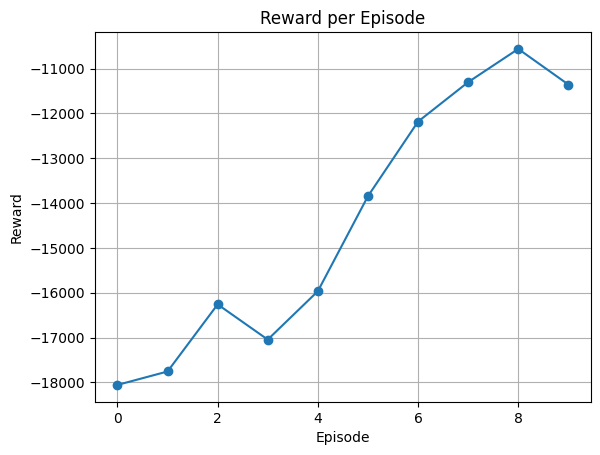

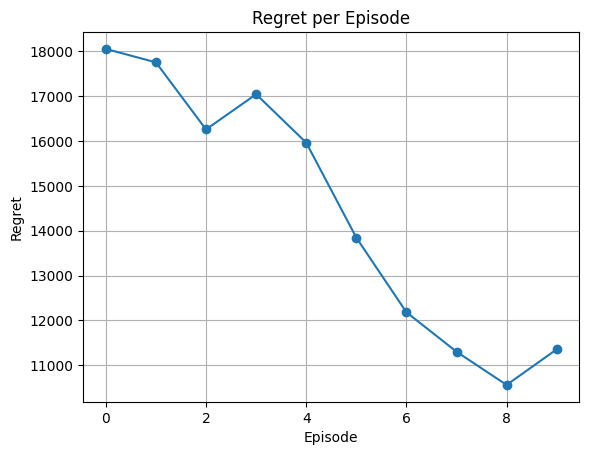

In [ ]:
# =============================================================
# MASAC + Transformer + Language→Reward/Constraint Compiler
# HVAC & Lighting, optional LLM/HITL (Colab-friendly, 4-bit)
# Progress bars enabled, full KPI logging to CSV
# =============================================================

# -----------------------
# Colab deps (optional)
# -----------------------
try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

if IN_COLAB:
    # Keep quiet; re-run if first install times out.
    !pip -q install --upgrade pip
    !pip -q install "transformers>=4.43" "accelerate>=0.33" "bitsandbytes>=0.43" \
                     sentencepiece safetensors huggingface_hub tqdm

# -----------------------
# CONFIG — tweak here
# -----------------------
CONFIG = dict(
    # episodes / logging
    NUM_EPISODES          = 1,
    LOG_EVERY             = 1000,
    SHOW_PROGRESS         = True,

    # training cadence (speed control)
    TRAIN_EVERY_K_STEPS   = 1,    # do updates every K env steps
    UPDATES_PER_TRAIN     = 1,    # gradient steps per train trigger
    MAX_STEPS_PER_EPISODE = None, # or an int to cap episode length

    # SAC
    TAU       = 0.01,
    GAMMA     = 0.99,
    ACTOR_LR  = 3e-4,
    CRITIC_LR = 1e-3,
    ALPHA_LR  = 3e-4,
    BATCH_SIZE  = 256,
    BUFFER_SIZE = 100_000,

    # Temporal encoder / attention
    EMBED_DIM  = 96,
    NUM_HEADS  = 4,
    NUM_LAYERS = 2,
    SEQ_LEN    = 8,
    TEMP_DIM   = 64,

    # Env/action bounds (defaults — PrefSpec can override)
    HVAC_MIN  = 21.0,
    HVAC_MAX  = 25.0,
    PMV_MIN   = -0.5,
    PMV_MAX   =  0.5,

    # Preferences: write free-form text here
    PREF_TEXT = (
        """
        Keep PMV tight (±0.25) during meetings; minimize peaks 14:00–18:00;
        CO2 under 0.45 kg/kWh; allow 21–25 °C; no change >0.3°C per step;
        comfort is very important; minimize CO2.
        """
    ),

    # LLM (4-bit, ephemeral) — HITL enabled
    LLM_ENABLED     = True,
    LLM_MODEL_ID    = "meta-llama/Llama-3.2-3B-Instruct",
    ICL_MAX_SHOTS   = 4,
    LLM_MAX_NEW_TOK = 64,
    LLM_TEMPERATURE = 0.08,

    # UI timeout (sec) — on timeout, defaults to LLM
    UI_TIMEOUT_S    = 20*60,

    # data path (resolved below)
    CSV_PATH        = None,
)

# -----------------------
# Resolve dataset path
# -----------------------
import os, glob, json, re, gc, time, random
from dataclasses import dataclass
from collections import deque, namedtuple
from typing import Dict, Any, List, Optional

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.distributions import Normal
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

if not CONFIG["CSV_PATH"] or not os.path.exists(str(CONFIG["CSV_PATH"])):
    # If you uploaded via files.upload() earlier, use that
    if "uploaded" in globals() and uploaded:
        CONFIG["CSV_PATH"] = next(iter(uploaded))
    else:
        csvs = sorted(glob.glob("*.csv"))
        if not csvs:
            raise FileNotFoundError("No CSV found. Upload with files.upload() in a prior cell or set CONFIG['CSV_PATH'].")
        CONFIG["CSV_PATH"] = csvs[0]
CSV_PATH = CONFIG["CSV_PATH"]
print("📁 Using CSV:", CSV_PATH)

# -----------------------
# CUDA mem before torch jobs
# -----------------------
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# JS bridge (Colab)
try:
    from google.colab import output as colab_output  # type: ignore
    _HAS_COLAB = True
except Exception:
    _HAS_COLAB = False

# -----------------------
# Derived globals
# -----------------------
TAU, GAMMA = CONFIG["TAU"], CONFIG["GAMMA"]
ACTOR_LR, CRITIC_LR, ALPHA_LR = CONFIG["ACTOR_LR"], CONFIG["CRITIC_LR"], CONFIG["ALPHA_LR"]
BATCH_SIZE, BUFFER_SIZE = CONFIG["BATCH_SIZE"], CONFIG["BUFFER_SIZE"]
EMBED_DIM, NUM_HEADS, NUM_LAYERS = CONFIG["EMBED_DIM"], CONFIG["NUM_HEADS"], CONFIG["NUM_LAYERS"]
SEQ_LEN, TEMP_DIM = CONFIG["SEQ_LEN"], CONFIG["TEMP_DIM"]
HVAC_MIN, HVAC_MAX, PMV_MIN, PMV_MAX = CONFIG["HVAC_MIN"], CONFIG["HVAC_MAX"], CONFIG["PMV_MIN"], CONFIG["PMV_MAX"]

LLM_ENABLED = bool(CONFIG.get("LLM_ENABLED", False))
MODEL_ID    = str(CONFIG.get("LLM_MODEL_ID", ""))

DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR   = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")
print("✔ Checkpoints →", CKPT_DIR)

EPS = 1e-6
ACTION_DIM, N_AGENTS = 1, 2

# HVAC–comfort/energy coupling (toy but smooth)
HVAC_SETPOINT_BASE = 23.0
COOL_SENSITIVITY   = 0.12
PMV_PER_DEG        = 0.15
COOL_CLAMP_MIN     = 0.30
COOL_CLAMP_MAX     = 1.20

# =============================================================
# Language → Reward/Constraint Compiler
# =============================================================
@dataclass
class PrefSpec:
    # Weights
    w_cost:  float = 1.0
    w_comf:  float = 1.0
    w_co2:   float = 0.0
    w_peak:  float = 0.0
    # Comfort band
    pmv_min: float = PMV_MIN
    pmv_max: float = PMV_MAX
    # CO₂ cap
    co2_cap_kg_per_kwh: Optional[float] = None
    # Peak window [h_start, h_end)
    peak_start_h: Optional[int] = None
    peak_end_h:   Optional[int] = None
    # Bounds & ramps
    sp_min: float = HVAC_MIN
    sp_max: float = HVAC_MAX
    max_sp_step: float = 0.5
    max_light_step: int = 15
    light_step: int = 5

# ------------- LLM helpers (4-bit, ephemeral) -------------
_tokenizer = _model = _device = None

def _load_llm_4bit(model_id: str):
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    bnb = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16
    )
    tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    mdl = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb,
        device_map="auto",
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    )
    mdl.config.use_cache = False
    mdl.eval()
    dev = next(mdl.parameters()).device
    print(f"🤖 LLM (4-bit) on: {dev}")
    return tok, mdl, dev

def _with_ephemeral_llm():
    global _tokenizer, _model, _device
    if not LLM_ENABLED:
        return
    if _model is None:
        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            _tokenizer, _model, _device = _load_llm_4bit(MODEL_ID)
        except Exception as e:
            print(f"⚠️ 4-bit load failed: {e}. Falling back to CPU offload.")
            from transformers import AutoTokenizer, AutoModelForCausalLM
            off_dir = "/content/offload"; os.makedirs(off_dir, exist_ok=True)
            _tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
            _model = AutoModelForCausalLM.from_pretrained(
                MODEL_ID, device_map="auto",
                max_memory={"cuda:0": "12GiB", "cpu": "48GiB"},
                offload_folder=off_dir,
            )
            _model.config.use_cache = False
            _device = next(_model.parameters()).device

def _free_llm():
    global _tokenizer, _model, _device
    try:
        del _model; del _tokenizer
    except Exception:
        pass
    _tokenizer = _model = _device = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def _chat(messages, max_new_tokens=CONFIG["LLM_MAX_NEW_TOK"], temperature=CONFIG["LLM_TEMPERATURE"], top_p=0.9):
    if not LLM_ENABLED or _model is None:
        return ""
    prompt = _tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = _tokenizer(prompt, return_tensors="pt").to(_device)
    with torch.no_grad():
        out = _model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=True,
            temperature=temperature, top_p=top_p, eos_token_id=_tokenizer.eos_token_id,
        )
    gen = out[0][inputs["input_ids"].shape[1]:]
    return _tokenizer.decode(gen, skip_special_tokens=True)

def _extract_json(text: str) -> Dict[str, Any]:
    s, e = text.find("{"), text.rfind("}")
    if s == -1 or e == -1 or e <= s:
        raise ValueError("No JSON in text.")
    return json.loads(text[s:e+1])

# ------------- NL → PrefSpec -------------
def compile_prefs_from_text(text: str, llm_fallback=True) -> PrefSpec:
    spec = PrefSpec()

    # PMV band: "[-0.2, 0.2]" or "±0.25"
    m = re.search(r'pmv[^0-9\-+]*\[?([\-+]?\d*\.?\d)\s*,\s*([\-+]?\d*\.?\d)\]?', text, re.I)
    if m:
        try:
            spec.pmv_min, spec.pmv_max = float(m.group(1)), float(m.group(2))
        except Exception:
            pass
    m = re.search(r'pmv[^0-9]*±\s*(\d*\.?\d)', text, re.I)
    if m:
        w = float(m.group(1)); spec.pmv_min, spec.pmv_max = -w, w

    # CO2 cap: "under 0.45 kg/kWh"
    m = re.search(r'co2[^0-9]*under[^0-9]*([\d\.]+)\s*kg\s*/\s*kwh', text, re.I)
    if m:
        spec.co2_cap_kg_per_kwh = float(m.group(1))

    # Peak window: "14:00–18:00" or "14-18"
    m = re.search(r'(?:peak|peaks?)\D*([01]?\d|2[0-3])(?::?\d\d)?\s*[–\-]\s*([01]?\d|2[0-3])', text, re.I)
    if m:
        spec.peak_start_h, spec.peak_end_h = int(m.group(1)), int(m.group(2))

    # Weights hints
    if re.search(r'minimi[sz]e cost', text, re.I): spec.w_cost = 1.0
    if re.search(r'comfort (is|as) (very )?important|keep pmv tight', text, re.I): spec.w_comf = 2.0
    if re.search(r'minimi[sz]e (co2|carbon)|co2 under', text, re.I): spec.w_co2 = 1.0
    if re.search(r'minimi[sz]e peaks?', text, re.I): spec.w_peak = 1.0

    # Setpoint bounds like: "21–25 °C"; ramp: "no change >0.3°C"
    m = re.search(r'(\d{2}(?:\.\d)?)\s*[–\-]\s*(\d{2}(?:\.\d)?)\s*°?c', text, re.I)
    if m:
        spec.sp_min, spec.sp_max = float(m.group(1)), float(m.group(2))
    m = re.search(r'no change[^0-9]*>\s*([\d\.]+)\s*°?c', text, re.I)
    if m:
        spec.max_sp_step = float(m.group(1))

    # Optional LLM fill
    if llm_fallback and LLM_ENABLED:
        _with_ephemeral_llm()
        try:
            schema = {
                "type": "object",
                "properties": {
                    "w_cost": {"type": "number"}, "w_comf": {"type": "number"},
                    "w_co2": {"type": "number"}, "w_peak": {"type": "number"},
                    "pmv_min": {"type": "number"}, "pmv_max": {"type": "number"},
                    "co2_cap_kg_per_kwh": {"type": ["number","null"]},
                    "peak_start_h": {"type": ["integer","null"]}, "peak_end_h": {"type": ["integer","null"]},
                    "sp_min": {"type": "number"}, "sp_max": {"type": "number"},
                    "max_sp_step": {"type": "number"},
                    "max_light_step": {"type": "integer"}, "light_step": {"type": "integer"}
                },
                "additionalProperties": False
            }
            sys = ("Extract a JSON object that fits this schema: " + json.dumps(schema) +
                   ". Fill N/A with null. Prefer conservative defaults for safety.")
            msg = [{"role": "system", "content": sys}, {"role": "user", "content": text}]
            out = _chat(msg, temperature=0.0, top_p=0.0)
            js = _extract_json(out)
            for k, v in js.items():
                if hasattr(spec, k) and v is not None:
                    cur = getattr(spec, k)
                    setattr(spec, k, type(cur)(v))
        except Exception:
            pass
        finally:
            _free_llm()
    return spec

# =============================================================
# Environment
# =============================================================
class DatasetEnv:
    """
    Two agents: HVAC setpoint (°C) and Lighting scale (0..1).
    Needs 'Date'; expects 'Cooling ', 'Fans', ' Pumps', 'Lighting'.
    Optional: 'Tariff' (or infer from 'Cost'), 'Grid_CO2'.
    Reward/constraints are driven by PrefSpec.
    """
    def __init__(self, csv: str, pref_spec: Optional[PrefSpec] = None):
        self.pref = pref_spec or PrefSpec()
        df = pd.read_csv(csv, parse_dates=['Date'])

        # time features
        dt   = df['Date']
        hour = dt.dt.hour + dt.dt.minute/60.0
        dow  = dt.dt.dayofweek
        mon  = dt.dt.month
        df['tod_sin'] = np.sin(2*np.pi*hour/24.0)
        df['tod_cos'] = np.cos(2*np.pi*hour/24.0)
        df['dow_sin'] = np.sin(2*np.pi*dow/7.0)
        df['dow_cos'] = np.cos(2*np.pi*dow/7.0)
        df['mon_sin'] = np.sin(2*np.pi*(mon-1)/12.0)
        df['mon_cos'] = np.cos(2*np.pi*(mon-1)/12.0)
        df['is_weekend'] = (dow>=5).astype(np.float32)

        # median tariff fallback
        def baseline_energy_row(r):
            return float(r.get('Cooling ',0.0))+float(r.get('Fans',0.0))+float(r.get(' Pumps',0.0))+float(r.get('Lighting',0.0))
        if 'Tariff' in df.columns and df['Tariff'].notna().any():
            self.median_tariff = float(pd.to_numeric(df['Tariff'], errors='coerce').dropna().median())
        else:
            valid = []
            for _, r in df.iterrows():
                be = baseline_energy_row(r)
                if be > 1e-6:
                    valid.append(float(r.get('Cost',0.0))/be)
            self.median_tariff = float(np.median(valid)) if len(valid) else 0.0

        self.df       = df.reset_index(drop=True)
        self.obs_cols = [c for c in self.df.columns if c != 'Date']
        self.obs_dim  = len(self.obs_cols)
        self.n        = len(self.df)
        self.idx      = 0

        # bounds for validators
        self.pmv_min = float(self.pref.pmv_min)
        self.pmv_max = float(self.pref.pmv_max)
        self.sp_min  = float(self.pref.sp_min)
        self.sp_max  = float(self.pref.sp_max)
        self.max_sp_step     = float(self.pref.max_sp_step)
        self.max_light_step  = int(self.pref.max_light_step)
        self.light_step      = int(self.pref.light_step)

    def _row_obs(self, i):
        return self.df.loc[i, self.obs_cols].values.astype(np.float32)

    def reset(self):
        self.idx = 0
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))
        return obs, self.df.loc[self.idx, 'Date']

    def step(self, hvac_sp: float, light_act: float):
        self.idx += 1
        done  = self.idx >= self.n - 1
        row   = self.df.loc[self.idx]
        date  = row['Date']

        cooling0 = float(row.get('Cooling ', 0.0))
        fans     = float(row.get('Fans', 0.0))
        pumps    = float(row.get(' Pumps', 0.0))
        light0   = float(row.get('Lighting', 0.0))

        # clamp bounds and do simple physics-ish coupling
        sp = float(np.clip(hvac_sp, self.sp_min, self.sp_max))
        delta_sp   = sp - HVAC_SETPOINT_BASE
        cool_scale = np.clip(1.0 - COOL_SENSITIVITY * delta_sp, COOL_CLAMP_MIN, COOL_CLAMP_MAX)
        cooling    = cool_scale * cooling0

        a_light   = float(np.clip(light_act, 0.0, 1.0))
        light_kwh = a_light * light0

        baseline_energy = cooling0 + fans + pumps + light0
        if baseline_energy > 1e-8:
            tariff = float(row.get('Tariff', row.get('Cost', 0.0)/baseline_energy))
        else:
            tariff = float(row.get('Tariff', self.median_tariff))

        grid_co2 = float(row.get('Grid_CO2', 0.4))  # kg/kWh default
        energy_kwh = cooling + fans + pumps + light_kwh
        cost       = tariff * energy_kwh

        pmv_base = row.get('Fanger PMV', row.get('PMV', 0.0))
        pmv      = float(pmv_base) + PMV_PER_DEG * delta_sp
        pmv_violation  = max(pmv - self.pmv_max, 0) + max(self.pmv_min - pmv, 0)

        # CO2 term (cap + absolute)
        co2_term = 0.0
        co2_kgh  = grid_co2 * energy_kwh
        if self.pref.co2_cap_kg_per_kwh is not None and grid_co2 > float(self.pref.co2_cap_kg_per_kwh):
            co2_term += (grid_co2 - float(self.pref.co2_cap_kg_per_kwh)) * energy_kwh
        co2_term += co2_kgh

        # Peak term
        peak_term = 0.0
        if (self.pref.peak_start_h is not None) and (self.pref.peak_end_h is not None):
            h = int(date.hour)
            if int(self.pref.peak_start_h) <= h < int(self.pref.peak_end_h):
                peak_term = energy_kwh

        # Weighted reward (negative costs)
        w = self.pref
        reward = -(
            w.w_cost * cost +
            w.w_comf * pmv_violation +
            w.w_co2  * co2_term +
            w.w_peak * peak_term
        )

        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))

        info = {**row.drop(labels=['Date']).to_dict(), 'date': date}
        info['Cooling ']   = cooling
        info['Lighting']   = light_kwh
        info['Light_scale']= a_light                 # NEW KPI
        info['Cost']       = cost
        info['Tariff']     = tariff
        info['Grid_CO2']   = grid_co2
        info['Fanger PMV'] = pmv
        info['PMV_violation'] = pmv_violation
        info['Net_kWh']    = energy_kwh
        info['Net_KWh']    = energy_kwh             # synonym
        info['Net_kWh_district'] = float(row.get('Net_kWh_district', energy_kwh))
        # breakdown for CSV aggregation later
        info['Reward_terms'] = {
            'cost': cost,
            'pmv_violation': pmv_violation,
            'co2_term': co2_term,
            'peak_term': peak_term,
            'weights': {'w_cost': w.w_cost, 'w_comf': w.w_comf, 'w_co2': w.w_co2, 'w_peak': w.w_peak}
        }
        return obs, reward, done, info

# =============================================================
# Replay Buffer
# =============================================================
Transition = namedtuple('T', ('obs','act','rew','nxt','done','seq','nseq'))
class ReplayBuffer:
    def __init__(self, cap): self.buf = deque(maxlen=cap)
    def push(self,*a):       self.buf.append(Transition(*a))
    def sample(self,b):      return random.sample(self.buf,b)
    def __len__(self):       return len(self.buf)

# =============================================================
# Temporal Encoder (Transformer)
# =============================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0), persistent=False)
    def forward(self, x):  # [B,L,D]
        return x + self.pe[:, :x.size(1)]

class TemporalEncoder(nn.Module):
    def __init__(self, input_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS):
        super().__init__()
        self.proj = nn.Linear(input_dim, model_dim)
        self.pos  = PositionalEncoding(model_dim, max_len=4096)
        enc = nn.TransformerEncoderLayer(
            d_model=model_dim, nhead=nhead, dim_feedforward=4*model_dim,
            activation='gelu', batch_first=True
        )
        self.tr = nn.TransformerEncoder(enc, num_layers=num_layers)
    def forward(self, seq):
        x = self.proj(seq)
        x = self.pos(x)
        x = self.tr(x)
        return x[:, -1, :]

# =============================================================
# Per-timestep Attention
# =============================================================
class MultiHeadAttention(nn.Module):
    def __init__(self, inp_dim, emb_dim, heads):
        super().__init__()
        assert emb_dim % heads == 0
        self.h = heads; self.hd = emb_dim // heads; self.scale = self.hd ** -0.5
        self.q_proj = nn.Linear(inp_dim, emb_dim)
        self.k_proj = nn.Linear(inp_dim, emb_dim)
        self.v_proj = nn.Linear(inp_dim, emb_dim)
        self.out    = nn.Linear(emb_dim, emb_dim)
    def forward(self, x):  # x: [B,N,TOKEN_DIM]
        B, N, _ = x.shape
        q = self.q_proj(x).view(B, self.h, N, self.hd)
        k = self.k_proj(x).view(B, self.h, N, self.hd)
        v = self.v_proj(x).view(B, self.h, N, self.hd)
        scores = (q @ k.transpose(-2, -1)) * self.scale
        w = F.softmax(scores, dim=-1)
        attn = (w @ v).transpose(1, 2).reshape(B, N, -1)
        return self.out(attn)

# =============================================================
# Actors / Critic
# =============================================================
def clamp_logstd(x): return x.clamp(-20, 2)

class BaseActor(nn.Module):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS,
                 token_index=0, squasher='tanh'):
        super().__init__()
        self.embed = nn.Linear(obs_dim, embed_dim)
        self.ctx_p = nn.Linear(ctx_dim, embed_dim)
        self.attn  = MultiHeadAttention(embed_dim, embed_dim, heads)
        self.mlp   = nn.Sequential(nn.Linear(embed_dim,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU())
        self.mu      = nn.Linear(256,1)
        self.log_std = nn.Linear(256,1)
        self.token_index = token_index
        self.squasher = squasher
    def forward(self, o, ctx):
        x = self.embed(o) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        h = self.mlp(x[:, self.token_index])
        mu, log_std = self.mu(h), clamp_logstd(self.log_std(h))
        return mu, log_std.exp()
    def sample(self, o, ctx):
        mu, std = self(o, ctx)
        dist = Normal(mu, std)
        z = dist.rsample()
        if self.squasher == 'tanh':
            r  = torch.tanh(z)
            a  = HVAC_MIN + (r + 1.0) * 0.5 * (HVAC_MAX - HVAC_MIN)
            logp = dist.log_prob(z) - torch.log(1 - r.pow(2) + EPS)
        else:
            a  = torch.sigmoid(z)
            logp = dist.log_prob(z) - torch.log(a*(1 - a) + EPS)
        return a, logp

class HVACActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__(obs_dim, ctx_dim, embed_dim, heads, token_index=0, squasher='tanh')

class LightingActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__(obs_dim, ctx_dim, embed_dim, heads, token_index=1, squasher='sigmoid')

class Critic(nn.Module):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__()
        self.oembed, self.aembed = nn.Linear(obs_dim,embed_dim), nn.Linear(1,embed_dim)
        self.ctx_p = nn.Linear(ctx_dim, embed_dim*2)
        self.attn  = MultiHeadAttention(embed_dim*2, embed_dim*2, heads)
        self.q     = nn.Sequential(nn.Linear(embed_dim*2*N_AGENTS,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU(),nn.Linear(256,1))
    def forward(self, o, a, ctx):
        x = torch.cat([self.oembed(o), self.aembed(a)], -1) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        return self.q(x.view(x.size(0),-1))

# =============================================================
# SAC Agent
# =============================================================
class MultiAgentSAC:
    def __init__(self, obs_dim, device='cpu'):
        self.device = device
        self.tau, self.gamma = TAU, GAMMA
        self.batch = BATCH_SIZE
        self.buf   = ReplayBuffer(BUFFER_SIZE)

        self.temporal = TemporalEncoder(obs_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS).to(device)
        self.actors   = nn.ModuleList([HVACActor(obs_dim), LightingActor(obs_dim)]).to(device)
        self.critic1  = Critic(obs_dim).to(device)
        self.critic2  = Critic(obs_dim).to(device)
        self.targ1    = Critic(obs_dim).to(device)
        self.targ2    = Critic(obs_dim).to(device)
        self.targ1.load_state_dict(self.critic1.state_dict())
        self.targ2.load_state_dict(self.critic2.state_dict())

        self.log_alpha = torch.tensor(0.0, requires_grad=True, device=device)
        self.aopt   = torch.optim.Adam(self.actors.parameters(), lr=ACTOR_LR)
        self.copt   = torch.optim.Adam(
            list(self.critic1.parameters()) +
            list(self.critic2.parameters()) +
            list(self.temporal.parameters()),
            lr=CRITIC_LR
        )
        self.alopt  = torch.optim.Adam([self.log_alpha], lr=ALPHA_LR)
        self.target_ent = -ACTION_DIM * N_AGENTS

    @property
    def alpha(self): return torch.exp(self.log_alpha)

    def _update_target(self):
        for tgt, src in ((self.targ1, self.critic1), (self.targ2, self.critic2)):
            for tp, sp in zip(tgt.parameters(), src.parameters()):
                tp.data.copy_(self.tau * sp.data + (1 - self.tau) * tp.data)

    def store(self, *args): self.buf.push(*args)

    def train_step(self):
        if len(self.buf) < self.batch: return
        batch = self.buf.sample(self.batch)
        dev = self.device

        obs = torch.stack([torch.tensor(x.obs, dtype=torch.float32, device=dev) for x in batch])
        act = torch.stack([torch.tensor(x.act, dtype=torch.float32, device=dev) for x in batch]).unsqueeze(-1)
        rew = torch.tensor([x.rew for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        nxt = torch.stack([torch.tensor(x.nxt, dtype=torch.float32, device=dev) for x in batch])
        don = torch.tensor([x.done for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        oseq = torch.stack([torch.tensor(x.seq,  dtype=torch.float32, device=dev) for x in batch])
        nseq = torch.stack([torch.tensor(x.nseq, dtype=torch.float32, device=dev) for x in batch])

        ctx  = self.temporal(oseq)
        nctx = self.temporal(nseq)

        with torch.no_grad():
            nas, lps = [], []
            for ac in self.actors:
                a, lp = ac.sample(nxt, nctx)
                nas.append(a); lps.append(lp)
            nas = torch.stack(nas, 1)
            lps = torch.stack(lps, 1).sum(dim=1)
            q1t = self.targ1(nxt, nas, nctx)
            q2t = self.targ2(nxt, nas, nctx)
            tgt = rew + (1 - don) * self.gamma * (torch.min(q1t, q2t) - self.alpha * lps)

        q1 = self.critic1(obs, act, ctx)
        q2 = self.critic2(obs, act, ctx)
        closs = F.mse_loss(q1, tgt) + F.mse_loss(q2, tgt)
        self.copt.zero_grad(); closs.backward(); self.copt.step()

        ctx_pi = ctx.detach()
        nas, lps = [], []
        for ac in self.actors:
            a, lp = ac.sample(obs, ctx_pi)
            nas.append(a); lps.append(lp)
        nas  = torch.stack(nas, 1)
        lps  = torch.stack(lps, 1).sum(1, keepdim=True)
        q1pi = self.critic1(obs, nas, ctx_pi)
        q2pi = self.critic2(obs, nas, ctx_pi)
        aloss = (self.alpha * lps - torch.min(q1pi, q2pi)).mean()
        self.aopt.zero_grad(); aloss.backward(); self.aopt.step()

        tloss = -(self.log_alpha * (lps + self.target_ent).detach()).mean()
        self.alopt.zero_grad(); tloss.backward(); self.alopt.step()

        self._update_target()

# =============================================================
# Checkpoints
# =============================================================
def _np_state_serialize():
    st = np.random.get_state()
    return (st[0], st[1].tolist(), st[2], st[3], st[4])

def _np_state_restore(st):
    if isinstance(st[1], list):
        st = (st[0], np.array(st[1], dtype=np.uint32), st[2], st[3], st[4])
    np.random.set_state(st)

def save_ckpt(ep, global_step, env, agent, fname=None, save_buffer=False):
    if fname is None:
        fname = f"ckpt_ep{ep:04d}_step{global_step:08d}.pt"
    path = os.path.join(CKPT_DIR, fname)
    ckpt = {
        "episode": ep, "global_step": global_step, "env_idx": getattr(env, "idx", 0),
        "actors":  agent.actors.state_dict(),
        "critic1": agent.critic1.state_dict(), "critic2": agent.critic2.state_dict(),
        "targ1":   agent.targ1.state_dict(),   "targ2":   agent.targ2.state_dict(),
        "temporal": agent.temporal.state_dict(),
        "aopt":  agent.aopt.state_dict(), "copt":  agent.copt.state_dict(), "alopt": agent.alopt.state_dict(),
        "log_alpha": float(agent.log_alpha.detach().cpu()),
        "rng_torch": torch.get_rng_state(), "rng_python": random.getstate(), "rng_numpy": _np_state_serialize(),
    }
    if save_buffer:
        ckpt["replay_buffer"] = list(agent.buf.buf)
    torch.save(ckpt, path)
    print(f"💾 Saved checkpoint → {path}")
    return path

def load_latest_ckpt(env, agent, device="cpu"):
    files = sorted(glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")))
    if not files:
        print("ℹ️ No checkpoint found. Starting fresh.")
        return 0, 0

    path = files[-1]
    ckpt = torch.load(path, map_location=device, weights_only=False)
    print(f"🔄 Resuming from {path}")

    # ---- models ----
    agent.actors.load_state_dict(ckpt["actors"])
    agent.critic1.load_state_dict(ckpt["critic1"])
    agent.critic2.load_state_dict(ckpt["critic2"])
    agent.targ1.load_state_dict(ckpt["targ1"])
    agent.targ2.load_state_dict(ckpt["targ2"])
    agent.temporal.load_state_dict(ckpt["temporal"])

    # ---- optimizers and alpha ----
    agent.log_alpha = torch.tensor(ckpt.get("log_alpha", 0.0), requires_grad=True, device=device)
    agent.alopt = torch.optim.Adam([agent.log_alpha], lr=agent.alopt.param_groups[0]["lr"])
    try:
        agent.aopt.load_state_dict(ckpt["aopt"])
    except Exception as e:
        print(f"⚠️ Could not load actor optimizer: {e}")
    try:
        agent.copt.load_state_dict(ckpt["copt"])
    except Exception as e:
        print(f"⚠️ Could not load critic optimizer: {e}")
    try:
        agent.alopt.load_state_dict(ckpt["alopt"])
    except Exception as e:
        print(f"⚠️ Could not load alpha optimizer: {e}")

    # ---- robust RNG restores (MUST be inside this function so `ckpt` is in scope) ----
    def _to_byte_state(x):
        if isinstance(x, torch.Tensor):
            return x.detach().to(device="cpu", dtype=torch.uint8)
        # handle Python lists/bytes/np arrays
        return torch.tensor(x, dtype=torch.uint8)

    if "rng_torch" in ckpt:
        try:
            torch.set_rng_state(_to_byte_state(ckpt["rng_torch"]))
        except Exception as e:
            print(f"⚠️ Skipping rng_torch restore: {e}")

    if "rng_python" in ckpt:
        try:
            random.setstate(ckpt["rng_python"])
        except Exception as e:
            print(f"⚠️ Skipping rng_python restore: {e}")

    if "rng_numpy" in ckpt:
        try:
            _np_state_restore(ckpt["rng_numpy"])
        except Exception as e:
            print(f"⚠️ Skipping rng_numpy restore: {e}")

    # ---- env index and return ----
    env.idx = ckpt.get("env_idx", 0)
    return int(ckpt["episode"]) + 1, int(ckpt["global_step"])

# =============================================================
# KPIs (episode-level from logged traces)
# =============================================================
def _agg_reward_terms(rt_list: List[Dict[str, Any]]) -> Dict[str, float]:
    if not rt_list:
        return dict(cost_sum=0.0, pmv_violation_sum=0.0, co2_term_sum=0.0, peak_term_sum=0.0)
    cost = sum(d.get('cost', 0.0) for d in rt_list)
    pmv  = sum(d.get('pmv_violation', 0.0) for d in rt_list)
    co2  = sum(d.get('co2_term', 0.0) for d in rt_list)
    peak = sum(d.get('peak_term', 0.0) for d in rt_list)
    return dict(cost_sum=float(cost), pmv_violation_sum=float(pmv), co2_term_sum=float(co2), peak_term_sum=float(peak))

def compute_kpis(hist, grid_price=None, grid_co2=None):
    pmv     = np.asarray(hist.get('Fanger PMV', []), dtype=float)
    cost    = np.asarray(hist.get('Cost', []), dtype=float)
    energy  = (np.asarray(hist.get('Cooling ', []), dtype=float) +
               np.asarray(hist.get('Fans',     []), dtype=float) +
               np.asarray(hist.get(' Pumps',   []), dtype=float) +
               np.asarray(hist.get('Lighting', []), dtype=float))
    light_s = np.asarray(hist.get('Light_scale', []), dtype=float)

    pmv_violation = np.maximum(pmv - PMV_MAX, 0) + np.maximum(PMV_MIN - pmv, 0)

    kpis = {
        'D_comf'      : float(np.mean(pmv_violation)) if pmv.size else 0.0,
        'C_cost'      : float(cost.sum()),
        'P_kWh'       : float(energy.sum()),
        'Light_mean'  : float(light_s.mean()) if light_s.size else 0.0,
        '1-L_ratio'   : float(1 - light_s.mean()) if light_s.size else 0.0,
        'R_reward'    : float(-(cost.sum() + pmv_violation.sum())),  # legacy baseline
    }

    # Aggregate reward-term breakdowns
    rt = _agg_reward_terms(hist.get('Reward_terms', []))
    kpis.update({
        'RT_cost_sum' : rt['cost_sum'],
        'RT_pmv_sum'  : rt['pmv_violation_sum'],
        'RT_co2_sum'  : rt['co2_term_sum'],
        'RT_peak_sum' : rt['peak_term_sum'],
    })

    # MERLIN-like extras if available
    net = hist.get('Net_kWh', None) or hist.get('Net_KWh', None)
    if (net is not None) and (grid_price is not None) and (grid_co2 is not None):
        net = np.asarray(net, dtype=float)
        gp  = np.asarray(grid_price, dtype=float)
        gc  = np.asarray(grid_co2, dtype=float)
        kpis.update({
            'D_elec' : float(np.maximum(0, net).sum()),
            'C_elec' : float(np.maximum(0, net*gp).sum()),
            'G_co2'  : float(np.maximum(0, net*gc).sum()),
            'Z_ZNE'  : float(net.sum()),
        })
        if len(net) >= 24:
            days = len(net)//24
            peaks = [net[i*24:(i+1)*24].max() for i in range(days)]
            kpis['P_peak'] = float(np.mean(peaks))
        else:
            kpis['P_peak'] = float(np.max(net) if len(net) else 0.0)
        kpis['R_ramp'] = float(np.abs(np.diff(net, prepend=net[0])).sum())
    return kpis

# =============================================================
# LLM ICL for 1st-step action (optional)
# =============================================================
def _clip(v, lo, hi): return float(min(max(v, lo), hi))
def _round_step(x: float, step: float) -> float: return round(round(x/step)*step, 10)

def _validate_action(action: Dict[str, Any], prev=None, spec: Optional[PrefSpec]=None):
    sp_min = spec.sp_min if spec else HVAC_MIN
    sp_max = spec.sp_max if spec else HVAC_MAX
    max_sp_step = spec.max_sp_step if spec else 0.5
    max_light_step = spec.max_light_step if spec else 15
    light_step = spec.light_step if spec else 5

    hvac_sp = float(action.get("hvac_sp", (sp_min+sp_max)/2))
    light   = int(action.get("light_pct", 70))
    if prev:
        hvac_sp = _clip(hvac_sp, prev.get("hvac_sp", hvac_sp)-max_sp_step, prev.get("hvac_sp", hvac_sp)+max_sp_step)
        light   = int(_clip(light, prev.get("light_pct", light)-max_light_step, prev.get("light_pct", light)+max_light_step))
    hvac_sp = _round_step(_clip(hvac_sp, sp_min, sp_max), 0.1)
    light   = int(_clip(int(round(light/light_step)*light_step), 0, 100))
    return {"hvac_sp": hvac_sp, "light_pct": light}

def _build_icl_shots_from_env_df(df: pd.DataFrame, spec: PrefSpec, max_shots=CONFIG["ICL_MAX_SHOTS"]) -> List[Dict[str, Any]]:
    def norm(x): return re.sub(r'[^a-z0-9]+','_', str(x).lower())
    cols_norm = {c: norm(c) for c in df.columns}
    def fnd(cands):
        for c, cn in cols_norm.items():
            if any(p in cn for p in cands): return c
        return None

    pmv_col   = fnd(["pmv","fanger","thermal_comfort"]) or 'Fanger PMV'
    cost_col  = fnd(["cost","energy_cost","electricity_cost","price"]) or 'Cost'
    tar_col   = fnd(["tariff","price_kwh","spot_price","tou"]) or 'Tariff'
    co2_col   = fnd(["co2_intensity","carbon_intensity","co2","g_per_kwh"]) or 'Grid_CO2'
    cool_col  = fnd(["cooling_kw","cooling","chiller"]) or 'Cooling '
    light_col = fnd(["lighting_kw","lighting","lights"]) or 'Lighting'
    dt_col    = fnd(["datetime","date_time","timestamp","date","time"]) or 'Date'

    dfd = df.copy()
    dt = pd.to_datetime(dfd[dt_col], errors="coerce")
    dfd["_hour"] = dt.dt.hour

    pmv_low  = float(pd.to_numeric(dfd[pmv_col], errors='coerce').quantile(0.15))
    pmv_high = float(pd.to_numeric(dfd[pmv_col], errors='coerce').quantile(0.85))

    def pick(mask):
        sub = dfd[mask].copy()
        if len(sub) == 0:
            return dfd.iloc[[np.random.default_rng(42).integers(0, len(dfd))]].iloc[0].to_dict()
        return sub.sample(1, random_state=42).iloc[0].to_dict()

    def is_peak_row(r):
        h = r.get("_hour", None)
        if h is None or pd.isna(h): return False
        if spec.peak_start_h is None or spec.peak_end_h is None: return False
        return int(spec.peak_start_h) <= int(h) < int(spec.peak_end_h)

    scenarios = [
        ("Warm+Peak",       pick( (pd.to_numeric(dfd[pmv_col], errors='coerce') >= pmv_high) & dfd.apply(is_peak_row, axis=1) )),
        ("Cool+Offpeak",    pick( (pd.to_numeric(dfd[pmv_col], errors='coerce') <= pmv_low)  & ~dfd.apply(is_peak_row, axis=1) )),
        ("Neutral+HighCO2", pick( dfd.apply(lambda r: abs(float(r.get(pmv_col,0.0))) <= 0.2 and float(r.get(co2_col,0.0)) >= float(spec.co2_cap_kg_per_kwh or 9e9), axis=1) )),
        ("Neutral+Peak",    pick( dfd.apply(lambda r: abs(float(r.get(pmv_col,0.0))) <= 0.2 and is_peak_row(r), axis=1) )),
    ]

    shots = []
    for name, row in scenarios[:max_shots]:
        def gf(col, default=0.0):
            val = row.get(col, default)
            try: return float(val)
            except Exception: return default
        state = {
            "time": str(row.get(dt_col, "auto")),
            "zone": "z3",
            "kpi": {
                "pmv": gf(pmv_col, 0.0),
                "cost": gf(cost_col, 0.0),
                "cooling_kw": gf(cool_col, 0.0),
                "lighting_kw": gf(light_col, 0.0),
                "co2_intensity_g_per_kwh": gf(co2_col, 0.0)*1000.0 if co2_col == 'Grid_CO2' else gf(co2_col, 0.0),
                "tariff": gf(tar_col, 0.0),
            },
            "previous_action": {"hvac_sp": (spec.sp_min+spec.sp_max)/2, "light_pct": 70},
            "constraints": {
                "pmv_min": spec.pmv_min, "pmv_max": spec.pmv_max,
                "sp_min": spec.sp_min,   "sp_max": spec.sp_max,
                "max_sp_step": spec.max_sp_step,
                "max_light_step": spec.max_light_step,
                "light_step": spec.light_step
            }
        }
        pmv = state["kpi"]["pmv"]; prev_sp = (spec.sp_min+spec.sp_max)/2; prev_l = 70
        sp_delta = -0.6 * pmv + (0.2 if ("Peak" in name) else 0.0)
        sp = _clip(prev_sp + sp_delta, prev_sp-spec.max_sp_step, prev_sp+spec.max_sp_step)
        sp = _round_step(_clip(sp, spec.sp_min, spec.sp_max), 0.1)
        if pmv > spec.pmv_max: light = max(prev_l-10, 20)
        elif pmv < spec.pmv_min: light = prev_l
        else: light = max(prev_l-10, 20) if ("Peak" in name) else prev_l
        light = int(_clip(int(round(light/spec.light_step)*spec.light_step), 0, 100))
        shots.append({"scenario": name, "state": state, "action": {"hvac_sp": sp, "light_pct": light}})
    return shots

_CTRL_SCHEMA = {
    "type": "object",
    "properties": {"hvac_sp": {"type": "number"}, "light_pct": {"type": "integer"}},
    "required": ["hvac_sp", "light_pct"], "additionalProperties": False
}
_SYSTEM_CTRL = (
    "You are an energy-control assistant. Return ONLY a JSON object matching this schema:\n"
    + json.dumps(_CTRL_SCHEMA) + "\n"
    "Goals: keep PMV within [pmv_min, pmv_max], minimize cost/CO₂ (tariff, co2_intensity_g_per_kwh), "
    "smooth actuation vs previous_action (ramp limits)."
)

def _build_ctrl_messages(state: Dict[str, Any], shots: List[Dict[str, Any]]):
    msgs = [{"role":"system","content":_SYSTEM_CTRL}]
    for ex in shots:
        msgs += [{"role":"user","content":"STATE:\n"+json.dumps(ex["state"])},
                 {"role":"assistant","content":json.dumps(ex["action"])}]
    msgs.append({"role":"user","content":"Propose ONE action for this STATE. Output must be JSON only:\n"+json.dumps(state)})
    return msgs

def _propose_action_llm(state: Dict[str, Any], shots: List[Dict[str, Any]], spec: PrefSpec):
    if not LLM_ENABLED: return None
    _with_ephemeral_llm()
    try:
        raw = _chat(_build_ctrl_messages(state, shots))
        if not raw:
            return None
        try:
            parsed = _extract_json(raw)
        except Exception:
            raw2 = re.sub(r"^[\s\S]*?{", "{", raw); raw2 = re.sub(r"}[\s\S]*$", "}", raw2)
            parsed = _extract_json(raw2)
        return _validate_action(parsed, prev=state.get("previous_action"), spec=spec)
    finally:
        _free_llm()

# =============================================================
# JS modal chooser (LLM / Manual)
# =============================================================
def get_user_action_js(ep_idx:int, ep_total:int, llm_suggest:dict|None, spec: PrefSpec,
                       timeout_s:int=CONFIG.get("UI_TIMEOUT_S", 20*60)) -> dict:
    """
    Returns {"mode":"llm"} or {"mode":"manual","action":{"hvac_sp":..,"light_pct":..}}
    On timeout or cancel → {"mode":"llm"}.
    """
    if not _HAS_COLAB:
        print(f"[Console] Ep {ep_idx}/{ep_total}. Type 'llm' or 'manual <sp> <light%>': ", end="")
        try:
            s = input().strip()
        except Exception:
            s = ""
        if s.startswith("manual"):
            try:
                _, sp, lp = s.split()
                return {"mode":"manual","action":{"hvac_sp": float(sp), "light_pct": int(lp)}}
            except Exception:
                pass
        return {"mode":"llm"}

    js = r"""
(async () => {
  const EP_IDX = __EP_IDX__;
  const EP_TOTAL = __EP_TOTAL__;
  const TIMEOUT_MS = __TIMEOUT_MS__;
  const HVAC_MIN = __HVAC_MIN__;
  const HVAC_MAX = __HVAC_MAX__;
  const SPMAXSTEP = __SP_MAX_STEP__;
  const LIGHTSTEP = __LIGHT_STEP__;
  const suggest = __SUGGEST_JSON__;

  function fmtSuggest(s) {
    if (!s || typeof s !== 'object') return '(none)';
    const sp = (typeof s.hvac_sp === 'number') ? s.hvac_sp.toFixed(1) : s.hvac_sp;
    const lt = (typeof s.light_pct === 'number') ? s.light_pct : '';
    return `hvac_sp=${sp}°C, light=${lt}%`;
  }

  return await new Promise((resolve) => {
    let done = false;
    const finish = (val) => { if (done) return; done = true; resolve(JSON.stringify(val)); };

    const modal = document.createElement('div');
    modal.style.cssText = 'position:fixed;inset:0;background:rgba(0,0,0,.25);z-index:999999;display:flex;align-items:flex-start;justify-content:center;';

    const box = document.createElement('div');
    box.style.cssText = 'margin-top:10vh;background:#fff;padding:16px 16px 12px;border-radius:12px;min-width:420px;box-shadow:0 8px 24px rgba(0,0,0,.2);font:14px/1.4 system-ui,Segoe UI,Roboto,Arial,sans-serif;';
    box.innerHTML = `
      <h3 style="margin:0 0 8px 0;">Episode ${EP_IDX}/${EP_TOTAL}</h3>
      <div><b>LLM suggestion:</b> ${fmtSuggest(suggest)}</div>
      <div style="margin-top:10px;">
        <label><input type="radio" name="mode" value="llm" checked> LLM (agent)</label>
        <label style="margin-left:16px;"><input type="radio" name="mode" value="manual"> Manual</label>
      </div>
      <div id="manual" style="opacity:.6;pointer-events:none;margin-top:8px;">
        <label>HVAC °C:
          <input id="hvac" type="number" step="0.1" min="${HVAC_MIN}" max="${HVAC_MAX}" value="${(suggest && typeof suggest.hvac_sp==='number') ? suggest.hvac_sp : (HVAC_MIN + HVAC_MAX)/2}">
        </label>
        <label style="margin-left:8px;">Light %:
          <input id="light" type="number" step="${LIGHTSTEP}" min="0" max="100" value="${(suggest && typeof suggest.light_pct==='number') ? suggest.light_pct : 70}">
        </label>
        <div style="margin-top:6px;font-size:12px;color:#444;">Max Δsetpoint per step = ${SPMAXSTEP}°C</div>
      </div>
      <div style="margin-top:12px;text-align:right;">
        <button id="ok" style="padding:6px 12px;">Apply</button>
        <button id="cancel" style="padding:6px 12px;margin-left:6px;">Cancel</button>
      </div>
    `;
    modal.appendChild(box);
    document.body.appendChild(modal);

    const manual = box.querySelector('#manual');
    const setManual = (on) => { manual.style.opacity = on ? '1' : '.6'; manual.style.pointerEvents = on ? 'auto' : 'none'; };
    for (const r of box.querySelectorAll('input[name=mode]')) {
      r.addEventListener('change', () => setManual(box.querySelector('input[name=mode]:checked').value === 'manual'));
    }

    box.querySelector('#ok').onclick = () => {
      const m = box.querySelector('input[name=mode]:checked').value;
      let out;
      if (m === 'llm') out = {mode:'llm'};
      else {
        const hv = parseFloat(box.querySelector('#hvac').value);
        const lt = parseInt(box.querySelector('#light').value);
        out = {mode:'manual', action:{hvac_sp: hv, light_pct: lt}};
      }
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish(out);
    };
    box.querySelector('#cancel').onclick = () => {
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish({mode:'llm'});
    };

    setManual(false);
    setTimeout(() => {
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish({mode:'llm'});
    }, TIMEOUT_MS);
  });
})();
"""
    js = (js
      .replace("__EP_IDX__", str(ep_idx))
      .replace("__EP_TOTAL__", str(ep_total))
      .replace("__TIMEOUT_MS__", str(int(timeout_s*1000)))
      .replace("__HVAC_MIN__", str(spec.sp_min))
      .replace("__HVAC_MAX__", str(spec.sp_max))
      .replace("__SP_MAX_STEP__", str(spec.max_sp_step))
      .replace("__LIGHT_STEP__", str(spec.light_step))
      .replace("__SUGGEST_JSON__", json.dumps(llm_suggest or {}))
    )
    result = colab_output.eval_js(js)
    try:
        return json.loads(result)
    except Exception:
        return {"mode":"llm"}

# =============================================================
# Training loop (HITL + Language→Reward)
# =============================================================
def train_agent_with_ui(csv=CSV_PATH, episodes_to_run=CONFIG["NUM_EPISODES"], log_every=CONFIG["LOG_EVERY"]):
    pref = compile_prefs_from_text(CONFIG.get("PREF_TEXT",""))
    print("🧭 PrefSpec:", pref)

    env    = DatasetEnv(csv, pref_spec=pref)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    agent  = MultiAgentSAC(env.obs_dim, device=device)

    start_ep, global_step = load_latest_ckpt(env, agent, device=device)
    end_ep = start_ep + int(episodes_to_run)
    total_eps = end_ep - start_ep
    print(f"💡 start_ep={start_ep}, end_ep={end_ep}, NUM_EPISODES={episodes_to_run}, global_step={global_step}")

    icl_shots = _build_icl_shots_from_env_df(env.df, spec=pref) if LLM_ENABLED else []

    first_write = not os.path.exists(METRICS_LIVE)
    kpi_hist, reward_hist, regret_hist = {}, [], []
    baseline = 0.0

    ep_iter = range(start_ep, end_ep)
    if CONFIG["SHOW_PROGRESS"]:
        ep_iter = tqdm(ep_iter, desc="Episodes", position=0, leave=True)

    for ep in ep_iter:
        obs, date = env.reset()
        done, ep_rew = False, 0.0

        # Optional LLM suggestion (first step)
        llm_suggest = None
        try:
            if LLM_ENABLED:
                row0 = env.df.loc[env.idx]
                state0 = {
                    "time": str(row0['Date']),
                    "zone": "z3",
                    "kpi": {
                        "pmv": float(row0.get('Fanger PMV', row0.get('PMV', 0.0))),
                        "cost": float(row0.get('Cost', 0.0)),
                        "tariff": float(row0.get('Tariff', env.median_tariff)),
                        "co2_intensity_g_per_kwh": float(row0.get('Grid_CO2', 0.0))*1000.0,
                        "cooling_kw": float(row0.get('Cooling ', 0.0)),
                        "lighting_kw": float(row0.get('Lighting', 0.0)),
                    },
                    "previous_action": {"hvac_sp": (pref.sp_min+pref.sp_max)/2, "light_pct": 70},
                    "constraints": {
                        "pmv_min": pref.pmv_min, "pmv_max": pref.pmv_max,
                        "sp_min": pref.sp_min, "sp_max": pref.sp_max,
                        "max_sp_step": pref.max_sp_step,
                        "max_light_step": pref.max_light_step,
                        "light_step": pref.light_step
                    }
                }
                llm_suggest = _propose_action_llm(state0, icl_shots, pref)
        except Exception as e:
            print(f"LLM suggestion failed: {e}")
            llm_suggest = None

        # HITL UI choice
        choice = get_user_action_js(ep_idx=ep+1, ep_total=end_ep, llm_suggest=llm_suggest, spec=pref, timeout_s=CONFIG["UI_TIMEOUT_S"])
        pending_action = None
        if choice.get("mode") == "manual":
            pending_action = _validate_action(choice["action"], prev={"hvac_sp":(pref.sp_min+pref.sp_max)/2,"light_pct":70}, spec=pref)
            print(f"🛠️ Using Manual action: {pending_action}")
        elif llm_suggest is not None:
            pending_action = llm_suggest
            print(f"🤖 Using LLM suggestion: {pending_action}")
        else:
            print("ℹ️ No LLM suggestion; falling back to policy for step-1.")

        # Temporal window bootstrap
        seq_deque = deque(maxlen=SEQ_LEN)
        raw0 = env._row_obs(env.idx)
        for _ in range(SEQ_LEN): seq_deque.append(raw0)

        # full info_hist with extra KPIs and Reward_terms list
        info_hist  = {k: [] for k in [
            'Cooling ','Fans',' Pumps','Lighting','Cost','Fanger PMV','PMV_violation',
            'Net_kWh','Net_KWh','Net_kWh_district','Tariff','Grid_CO2','Light_scale'
        ]}
        info_hist['Reward_terms'] = []  # list of dicts for later aggregation
        price_trace, co2_trace = [], []

        steps_total = max(env.n - 1, 1)
        step_idx = 0
        step_bar = None
        if CONFIG["SHOW_PROGRESS"]:
            step_bar = tqdm(total=steps_total, desc=f"Ep {ep+1}/{end_ep} steps", position=1, leave=False)

        while not done:
            if global_step and global_step % log_every == 0:
                print(f"  ↳ Ep {ep+1}/{end_ep} • Step {step_idx+1}/{steps_total} • Global {global_step:,}")

            # Build context
            seq_np = np.stack(list(seq_deque), axis=0)
            seq_t  = torch.tensor(seq_np, dtype=torch.float32, device=device).unsqueeze(0)
            ctx    = agent.temporal(seq_t).squeeze(0)
            obs_t  = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)

            # Choose action
            if step_idx == 0 and pending_action is not None:
                hvac_sp   = float(pending_action["hvac_sp"])
                light_pct = int(pending_action["light_pct"])
                act = [hvac_sp, light_pct / 100.0]
            else:
                hvac,_  = agent.actors[0].sample(obs_t, ctx.unsqueeze(0))
                light,_ = agent.actors[1].sample(obs_t, ctx.unsqueeze(0))
                act = [hvac.item(), light.item()]

            # Step env
            nxt, rew, done, info = env.step(*act)
            ep_rew += rew
            global_step += 1
            step_idx += 1
            if step_bar is not None:
                step_bar.update(1)

            # Prepare next state and sequences
            raw_next = nxt[0].astype(np.float32)
            nseq_np  = np.concatenate([seq_np[1:], raw_next[None, :]], axis=0)

            # Buffer + training cadence
            agent.store(obs, act, rew, nxt, done, seq_np, nseq_np)
            if (global_step % int(CONFIG["TRAIN_EVERY_K_STEPS"])) == 0:
                for _ in range(int(CONFIG["UPDATES_PER_TRAIN"])):
                    agent.train_step()

            # Advance state
            obs = nxt
            seq_deque.append(raw_next)

            # Logging (numerics)
            for k in info_hist:
                if k != 'Reward_terms' and k in info:
                    info_hist[k].append(info.get(k, 0.0))
            price_trace.append(info.get('Tariff', 0.0))
            co2_trace.append(info.get('Grid_CO2', 0.0))
            # reward-term dicts
            if 'Reward_terms' in info:
                info_hist['Reward_terms'].append(info['Reward_terms'])

            # Optional per-episode step cap
            if CONFIG.get("MAX_STEPS_PER_EPISODE"):
                if step_idx >= int(CONFIG["MAX_STEPS_PER_EPISODE"]):
                    done = True

        if step_bar is not None: step_bar.close()

        # KPIs, log, checkpoint
        kpis = compute_kpis(info_hist, grid_price=price_trace, grid_co2=co2_trace)
        if not kpi_hist: kpi_hist = {k: [] for k in kpis}
        for k,v in kpis.items(): kpi_hist[k].append(v)

        print(f"✓ Episode {ep+1:02d}/{end_ep}  reward={ep_rew:,.2f}")
        row = {**kpis, "Reward": ep_rew, "Regret": baseline - ep_rew, "Episode": ep+1}
        pd.DataFrame([row]).to_csv(METRICS_LIVE, mode='a', header=first_write, index=False)
        first_write = False
        save_ckpt(ep, global_step, env, agent, save_buffer=False)

    # Final CSV & plots
    df_all = pd.read_csv(METRICS_LIVE) if os.path.exists(METRICS_LIVE) else \
             pd.DataFrame({**kpi_hist, 'Reward': reward_hist, 'Regret': regret_hist})
    out_csv = 'run_metrics.csv'
    df_all.to_csv(out_csv, index=False)
    print(f"\n📄 Saved full KPI history to {out_csv}")
    try:
        if IN_COLAB:
            from google.colab import files
            files.download(out_csv)
            print("⬇️ KPI CSV download triggered.")
    except ModuleNotFoundError:
        pass

    if 'Reward' in df_all.columns and len(df_all):
        plt.figure(); plt.plot(df_all['Reward'], marker='o'); plt.title('Reward per Episode'); plt.xlabel("Episode"); plt.ylabel("Reward"); plt.grid(True)
        plt.figure(); plt.plot(df_all['Regret'], marker='o'); plt.title('Regret per Episode'); plt.xlabel("Episode"); plt.ylabel("Regret"); plt.grid(True)
        plt.show()

# =============================================================
# GO
# =============================================================
if __name__ == "__main__":
    train_agent_with_ui(csv=CONFIG["CSV_PATH"], episodes_to_run=CONFIG["NUM_EPISODES"], log_every=CONFIG["LOG_EVERY"])


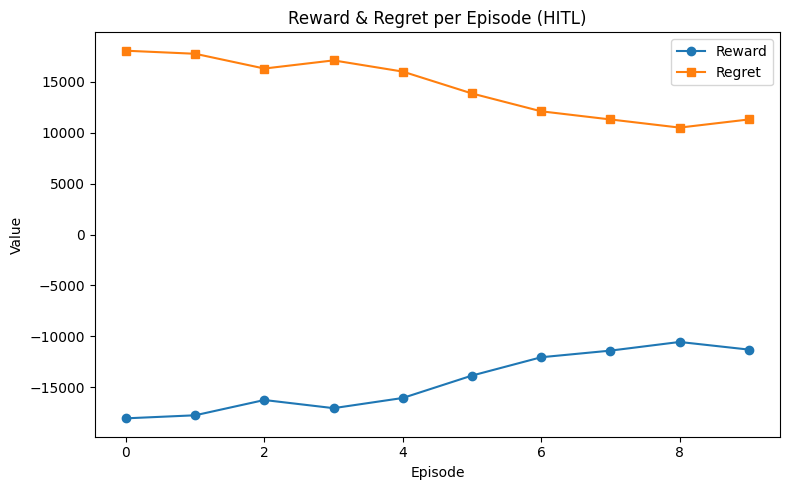

In [ ]:
# Reward & Regret on a single shared episode index (no gridlines)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === Use these corrected values from your plots ===
y_reward = [-18050, -17750, -16250, -17050, -16050, -13850, -12050, -11400, -10550, -11300]
y_regret = [ 18050,  17750,  16300,  17100,  16000,  13850,  12100,  11300,  10500,  11300]

# --- Build ONE shared index (Episode 0..N-1) that contains BOTH series ---
N = min(len(y_reward), len(y_regret))
episode = np.arange(N)

# Keep data in a tidy table with the shared index
df = pd.DataFrame({"Reward": y_reward[:N], "Regret": y_regret[:N]}, index=episode)
df.index.name = "Episode"

# (Optional) save the index + values
# df.to_csv("hitl_reward_regret_index.csv")

# --- Plot both series on the same axes using that single index; no gridlines ---
plt.figure(figsize=(8, 5))
plt.plot(df.index, df["Reward"], marker="o", label="Reward")
plt.plot(df.index, df["Regret"], marker="s", label="Regret")
plt.title("Reward & Regret per Episode (HITL)")
plt.xlabel("Episode")
plt.ylabel("Value")
plt.legend()
plt.grid(False)  # no gridlines
plt.tight_layout()
plt.show()